IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

LOAD DATASET

In [2]:
df = pd.read_csv('CustomerChurnPrediction.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Basic Dataset Info

In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Churn"].value_counts())

print("\nTarget Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

Data cleaning

In [4]:
# Remove customerID because it is an identifier
df.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges into numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

Cleaned Dataset Shape: (7043, 20)

Missing Values After Cleaning:
0


Exploratory data analysis

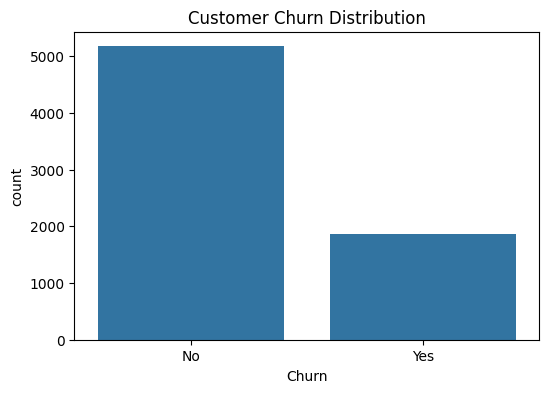

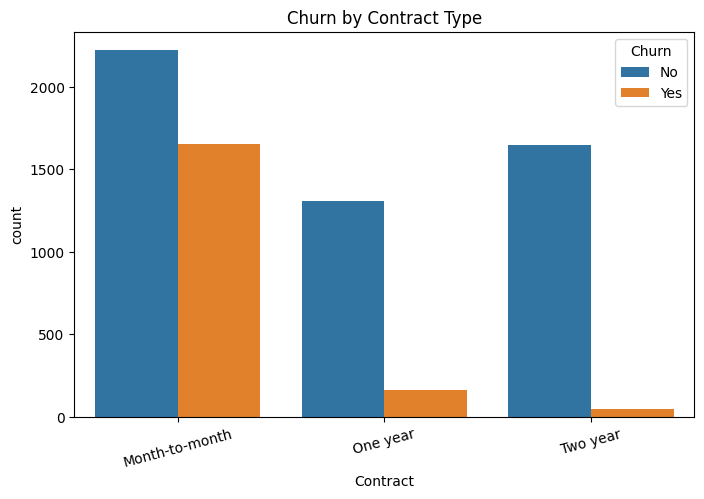

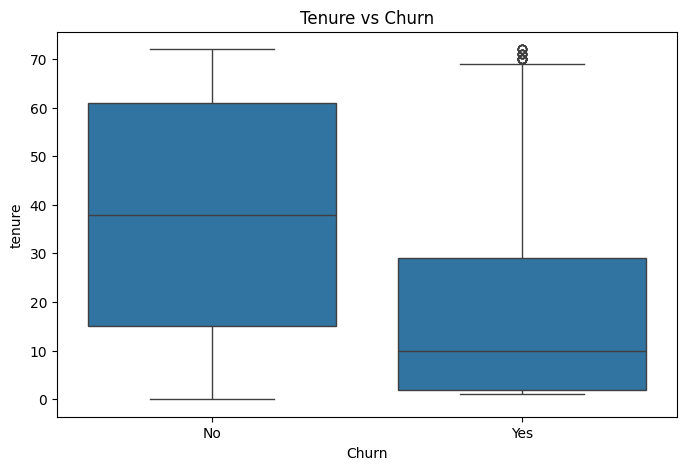

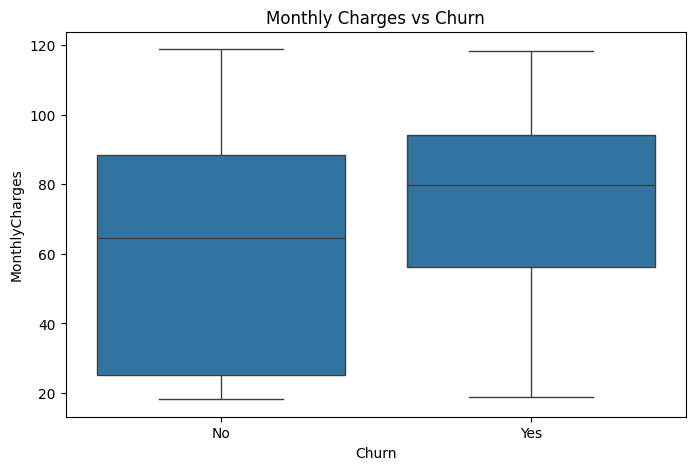

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Churn")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

Target encoding

In [6]:
# Remove extra spaces from target values
df["Churn"] = df["Churn"].astype(str).str.strip()

# Check target values before encoding
print("Target values before encoding:")
print(df["Churn"].value_counts(dropna=False))

# Convert Yes/No into 1/0
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Check missing values
print("\nMissing values in Churn:", df["Churn"].isnull().sum())

# Remove rows where target is missing or invalid
df = df.dropna(subset=["Churn"]).copy()

# Convert target to integer
df["Churn"] = df["Churn"].astype(int)

print("\nTarget distribution after cleaning:")
print(df["Churn"].value_counts())

Target values before encoding:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing values in Churn: 0

Target distribution after cleaning:
Churn
0    5174
1    1869
Name: count, dtype: int64


split

In [7]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("Missing values in y:", y.isnull().sum())


Features Shape: (7043, 19)
Target Shape: (7043,)
Missing values in y: 0


Train, validation and test split

In [8]:
# First split: 80% train+validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 80% train, 20% validation from train+validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

Training Set: (4507, 19)
Validation Set: (1127, 19)
Testing Set: (1409, 19)


Identify numerical categorial col

In [9]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Preprocessing pipline

In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="passthrough"
)

Logistic Regression model

In [11]:

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained!")

Logistic Regression Model Trained!


Validation Predictions

In [12]:
val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

# Previously selected threshold based on recall priority
logistic_threshold = 0.40

val_predictions = (
    val_probabilities >= logistic_threshold
).astype(int)

print("Validation Results")
print("Accuracy:", accuracy_score(y_val, val_predictions))
print("Precision:", precision_score(y_val, val_predictions))
print("Recall:", recall_score(y_val, val_predictions))
print("F1 Score:", f1_score(y_val, val_predictions))

Validation Results
Accuracy: 0.7000887311446318
Precision: 0.46511627906976744
Recall: 0.8695652173913043
F1 Score: 0.6060606060606061


Random Forest Model

In [13]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained!")

Random Forest Model Trained!


Random forest validation

In [14]:
rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

rf_threshold = 0.30

rf_val_predictions = (
    rf_val_probabilities >= rf_threshold
).astype(int)

print("Random Forest Validation Results")
print("Accuracy:", accuracy_score(y_val, rf_val_predictions))
print("Precision:", precision_score(y_val, rf_val_predictions))
print("Recall:", recall_score(y_val, rf_val_predictions))
print("F1 Score:", f1_score(y_val, rf_val_predictions))

Random Forest Validation Results
Accuracy: 0.7471162377994676
Precision: 0.5165094339622641
Recall: 0.7324414715719063
F1 Score: 0.6058091286307054


Model comparison on validation data

In [15]:
comparison = pd.DataFrame({
    "Model": [
        "Balanced Logistic Regression",
        "Random Forest"
    ],
    "Threshold": [
        logistic_threshold,
        rf_threshold
    ],
    "Accuracy": [
        accuracy_score(y_val, val_predictions),
        accuracy_score(y_val, rf_val_predictions)
    ],
    "Precision": [
        precision_score(y_val, val_predictions),
        precision_score(y_val, rf_val_predictions)
    ],
    "Recall": [
        recall_score(y_val, val_predictions),
        recall_score(y_val, rf_val_predictions)
    ],
    "F1 Score": [
        f1_score(y_val, val_predictions),
        f1_score(y_val, rf_val_predictions)
    ]
})

display(comparison)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Balanced Logistic Regression,0.4,0.700089,0.465116,0.869565,0.606061
1,Random Forest,0.3,0.747116,0.516509,0.732441,0.605809


Final Model selection

In [16]:
# Select Logistic Regression because our main objective
# is to identify as many potential churn customers as possible.

final_model = logistic_model
final_threshold = logistic_threshold

print("Selected Model: Balanced Logistic Regression")
print("Selected Threshold:", final_threshold)


Selected Model: Balanced Logistic Regression
Selected Threshold: 0.4


Final test prediction

In [17]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)


Final model eual

In [18]:
accuracy = accuracy_score(y_test, test_predictions)
precision = precision_score(y_test, test_predictions)
recall = recall_score(y_test, test_predictions)
f1 = f1_score(y_test, test_predictions)
roc_auc = roc_auc_score(y_test, test_probabilities)
pr_auc = average_precision_score(y_test, test_probabilities)

print("FINAL TEST RESULTS")
print("------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))
print("PR-AUC   :", round(pr_auc, 4))

FINAL TEST RESULTS
------------------------------
Accuracy : 0.7005
Precision: 0.4658
Recall   : 0.8743
F1 Score : 0.6078
ROC-AUC  : 0.8424
PR-AUC   : 0.6332


Classification Report

In [19]:
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.93      0.64      0.76      1035
       Churn       0.47      0.87      0.61       374

    accuracy                           0.70      1409
   macro avg       0.70      0.76      0.68      1409
weighted avg       0.81      0.70      0.72      1409



Confusion matrix

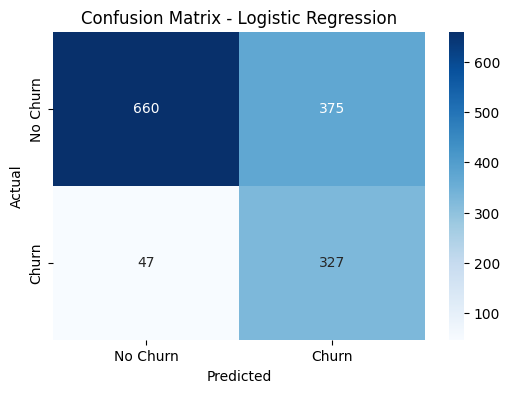

True Negatives : 660
False Positives: 375
False Negatives: 47
True Positives : 327


In [20]:
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

Roc- curv

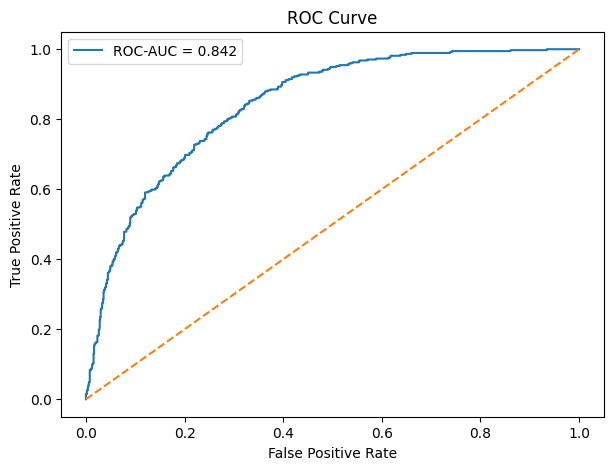

In [21]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Feature coffe

In [22]:

# Get transformed feature names
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = final_model.named_steps[
    "classifier"
].coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficient_df.head(15))

,Feature,Coefficient,Absolute Coefficient
25,cat__Contract_Two year,-1.558594,1.558594
10,cat__InternetService_Fiber optic,1.161785,1.161785
1,num__tenure,-1.148240,1.148240
24,cat__Contract_One year,-0.747697,0.747697
3,num__TotalCharges,0.486924,0.486924
2,num__MonthlyCharges,-0.443426,0.443426
21,cat__StreamingTV_Yes,0.388488,0.388488
23,cat__StreamingMovies_Yes,0.367702,0.367702
9,cat__MultipleLines_Yes,0.347253,0.347253
7,cat__PhoneService_Yes,-0.341909,0.341909


Save final model

In [23]:
model_artifact = {
    "model": final_model,
    "threshold": final_threshold,
    "model_name": "Balanced Logistic Regression",
    "feature_columns": X.columns.tolist()
}

joblib.dump(
    model_artifact,
    "telco_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Test saved model

In [24]:
loaded_artifact = joblib.load("telco_churn_model.pkl")

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

sample = X_test.iloc[[0]]

sample_probability = loaded_model.predict_proba(sample)[:, 1][0]

sample_prediction = int(
    sample_probability >= loaded_threshold
)

print("Churn Probability:", round(sample_probability, 4))

if sample_prediction == 1:
    print("Prediction: Customer likely to churn")
else:
    print("Prediction: Customer likely to stay")

Churn Probability: 0.1039
Prediction: Customer likely to stay
